In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.exists("../common") else os.path.abspath(os.getcwd())
if "google.colab" in sys.modules:
    print("⚡ Google Colab 環境を検出しました。リポジトリのセットアップを開始します...")
    !git clone https://github.com/miyayudai/study-mikanos.git /content/study-mikanos 2>/dev/null || (cd /content/study-mikanos && git pull)
    %cd /content/study-mikanos
    !pip install -q -r requirements.txt
    !pip install -q -e .
    repo_root = "/content/study-mikanos"
    sys.path.insert(0, repo_root)
    print("✅ 環境セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    if repo_root not in sys.path:
        sys.path.insert(0, repo_root)
    print("💻 ローカル開発環境を検出しました。リポジトリルート:", repo_root)


💻 ローカル開発環境を検出しました。リポジトリルート: /home/student/Documents/GitHub/study-mikanos


# 8.3 データ構造の移動 (`osbook_day08b`)
### *Relocating Kernel Data Structures & Lifetime Isolation*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/8/8.3_Relocating_Kernel_Data_Structures.ipynb)

---

## 🎯 本節の目的と学習到達目標

前節（8.2節）では、ブートローダ（`MikanLoaderPkg/Main.c`）からカーネルのエントリポイント（`KernelMain`）へメモリマップを引き渡し、UEFIの物理メモリディスクリプタを走査して利用可能な物理 RAM を特定する手法を確立しました。

しかし、ここには **OS 起動直後における最も致命的な落とし穴（過渡的メモリの罠）** が潜んでいます。

ブートローダから渡された引数 `frame_buffer_config` や `memory_map` は、依然として **UEFI ブートローダのスタック領域（`EfiLoaderData` または `EfiBootServicesData`）** に存在しています。
`ExitBootServices()` を呼んだ後、OS はこれらの領域を「空きメモリ（再利用可能メモリ）」として扱います。もし OS のメモリマネージャが稼働してこの領域を上書きしたらどうなるでしょうか？
カーネル自身の画面設定やメモリマップ情報がゴミデータで上書きされ、**OS は即座にクラッシュ（Page Fault / トリプルフォルト）** してしまいます！

本節（`osbook_day08b`）では、これらの重要データ構造をカーネル管理下の独立したメモリ領域（カーネルスタック）へ **安全に値コピー退避（Relocation）** させるアーキテクチャを学びます。

### 📖 本節の主要学習トピック
1. **過渡的 UEFI メモリの危険性**:
   - `ExitBootServices()` 後のメモリ解放ライフサイクルと、ブートローダスタックの脆弱性。
   - 参照渡しのポインタが「ダングリングポインタ（Dangling Pointer）」化するメカニズム。
2. **C++ コピーコンストラクタによる値コピー退避**:
   - `KernelMainNewStack` におけるローカル変数へのコピー生成（`FrameBufferConfig{ref}`, `MemoryMap{ref}`）。
   - コピーによるメモリ空間の完全分離とスタックフレームの移行。
3. **ディープコピー vs シャローコピーの境界線**:
   - `MemoryMap` の `buffer` メンバ（ポインタ）が抱えるシャローコピーの性質。
   - なぜ MikanOS ではバッファ自体のディープコピーを行わなくても安全なのか（走査フェーズと確保フェーズの分離数理）。
4. **`IsAvailable()` カプセル化による判定整理**:
   - `kernel/memory_map.hpp` での `IsAvailable()` インライン関数の導入と線形探索ループのリファクタリング。
   - `kUEFIPageSize = 4096` 定数の導入。


---

## 1. なぜデータ構造の退避（Relocation）が必要なのか？

### 1.1 ブートローダスタックの生存期間（Lifetime of UEFI Stack）

UEFI アプリケーションとして動作するブートローダ（`MikanLoaderPkg/Main.c`）において、ローカル変数として宣言された `FrameBufferConfig config` や `MemoryMap memmap` は、**UEFI ファームウェアがブートローダ用に割り当てたスタック領域** に配置されます。

```
+-------------------------------------------------------------+
| UEFI ファームウェア管理領域 (0x0700_0000 - 0x07FF_FFFF 付近)   |
|   - EfiBootServicesData / EfiLoaderData                     |
|   +-------------------------------------------------------+ |
|   | ブートローダ スタック (RSP ~ 0x07EE_F000)                | |
|   |   - struct FrameBufferConfig config  <---+            | |
|   |   - struct MemoryMap memmap          <---|----+       | |
|   +------------------------------------------|----|-------+ |
+----------------------------------------------|----|---------+
                                               |    |
カーネル呼び出し:                                |    |
  KernelMain(config, memmap);                  |    |
             |       |                         |    |
             |       +--- %rsi (第2引数ポインタ)-+    |
             +----------- %rdi (第1引数ポインタ)------+
```

ブートローダが `KernelMain(&config, &memmap)` を呼び出したとき、C++ カーネル側の引数は次のように受け取っていました（8.2節）：

```cpp
extern "C" void KernelMain(const FrameBufferConfig& frame_buffer_config,
                           const MemoryMap& memory_map);
```

C++ の参照型（`const T&`）は、内部的には **アドレスを指すポインタ（Pointer）** として実装されます。
したがって、カーネル内で `frame_buffer_config.frame_buffer` や `memory_map.buffer` にアクセスするたびに、CPU は **古い UEFI スタック領域（`0x07EE_F000` 番地付近）を読みに行っている** のです！

### 1.2 `ExitBootServices()` 後のメモリ解放と再利用のメカニズム

ブートローダは、カーネルに制御を渡す直前に `gBS->ExitBootServices()` を呼び出しています。
この API が成功した瞬間、UEFI のブートサービス用コード・データ領域（`EfiBootServicesCode`, `EfiBootServicesData`）はすべてファームウェアの手を離れ、**「OS が自由に再利用してよい物理 RAM（空きメモリ）」** へと変化します。

前節（8.2節）で実装した `IsAvailable()` を思い出してください：
```cpp
inline bool IsAvailable(MemoryType memory_type) {
  return
    memory_type == MemoryType::kEfiBootServicesCode ||
    memory_type == MemoryType::kEfiBootServicesData ||
    memory_type == MemoryType::kEfiConventionalMemory;
}
```
OS はこれらの領域をすべて「利用可能な空き RAM」としてカウントしています。

### 1.3 【致命傷シナリオ】未退避の参照が引き起こすメモリ破壊

もしカーネルが引数をポインタ参照のまま保持し続けた場合、次のような壊滅的連鎖が発生します：

1. **フェーズ 1**: カーネルが初期化を進め、デバイスドライバ用バッファや動的メモリ管理（ヒープ）を開始する。
2. **フェーズ 2**: メモリマネージャは「空き領域」としてリストされている `EfiBootServicesData`（古い UEFI スタックがあった場所）を新規割り当てバッファとして払い出す。
3. **フェーズ 3**: 他の処理がそのバッファにデータを書き込んだ瞬間、古い UEFI スタック上の `frame_buffer_config` や `memory_map` が **ゼロクリアまたはゴミデータで上書きされる**！
4. **フェーズ 4**: カーネルが画面描画（`pixel_writer->Write()`）を呼ぶと、`frame_buffer` のアドレスが `0x0000_0000`（またはゴミポインタ）になっているため、**Page Fault 例外（#PF）が発生し、OS は即座にトリプルフォルトでリブート** します。


---

## 2. Figure 8.7: UEFI過渡的メモリの危険性とデータ破壊のメカニズム

このメモリ破壊のメカニズムを視覚化したのが以下の図版です。
上段はブートローダから渡された直後の脆弱な参照関係、下段は OS のメモリ再利用によってスタックが破壊されるシナリオを示しています。


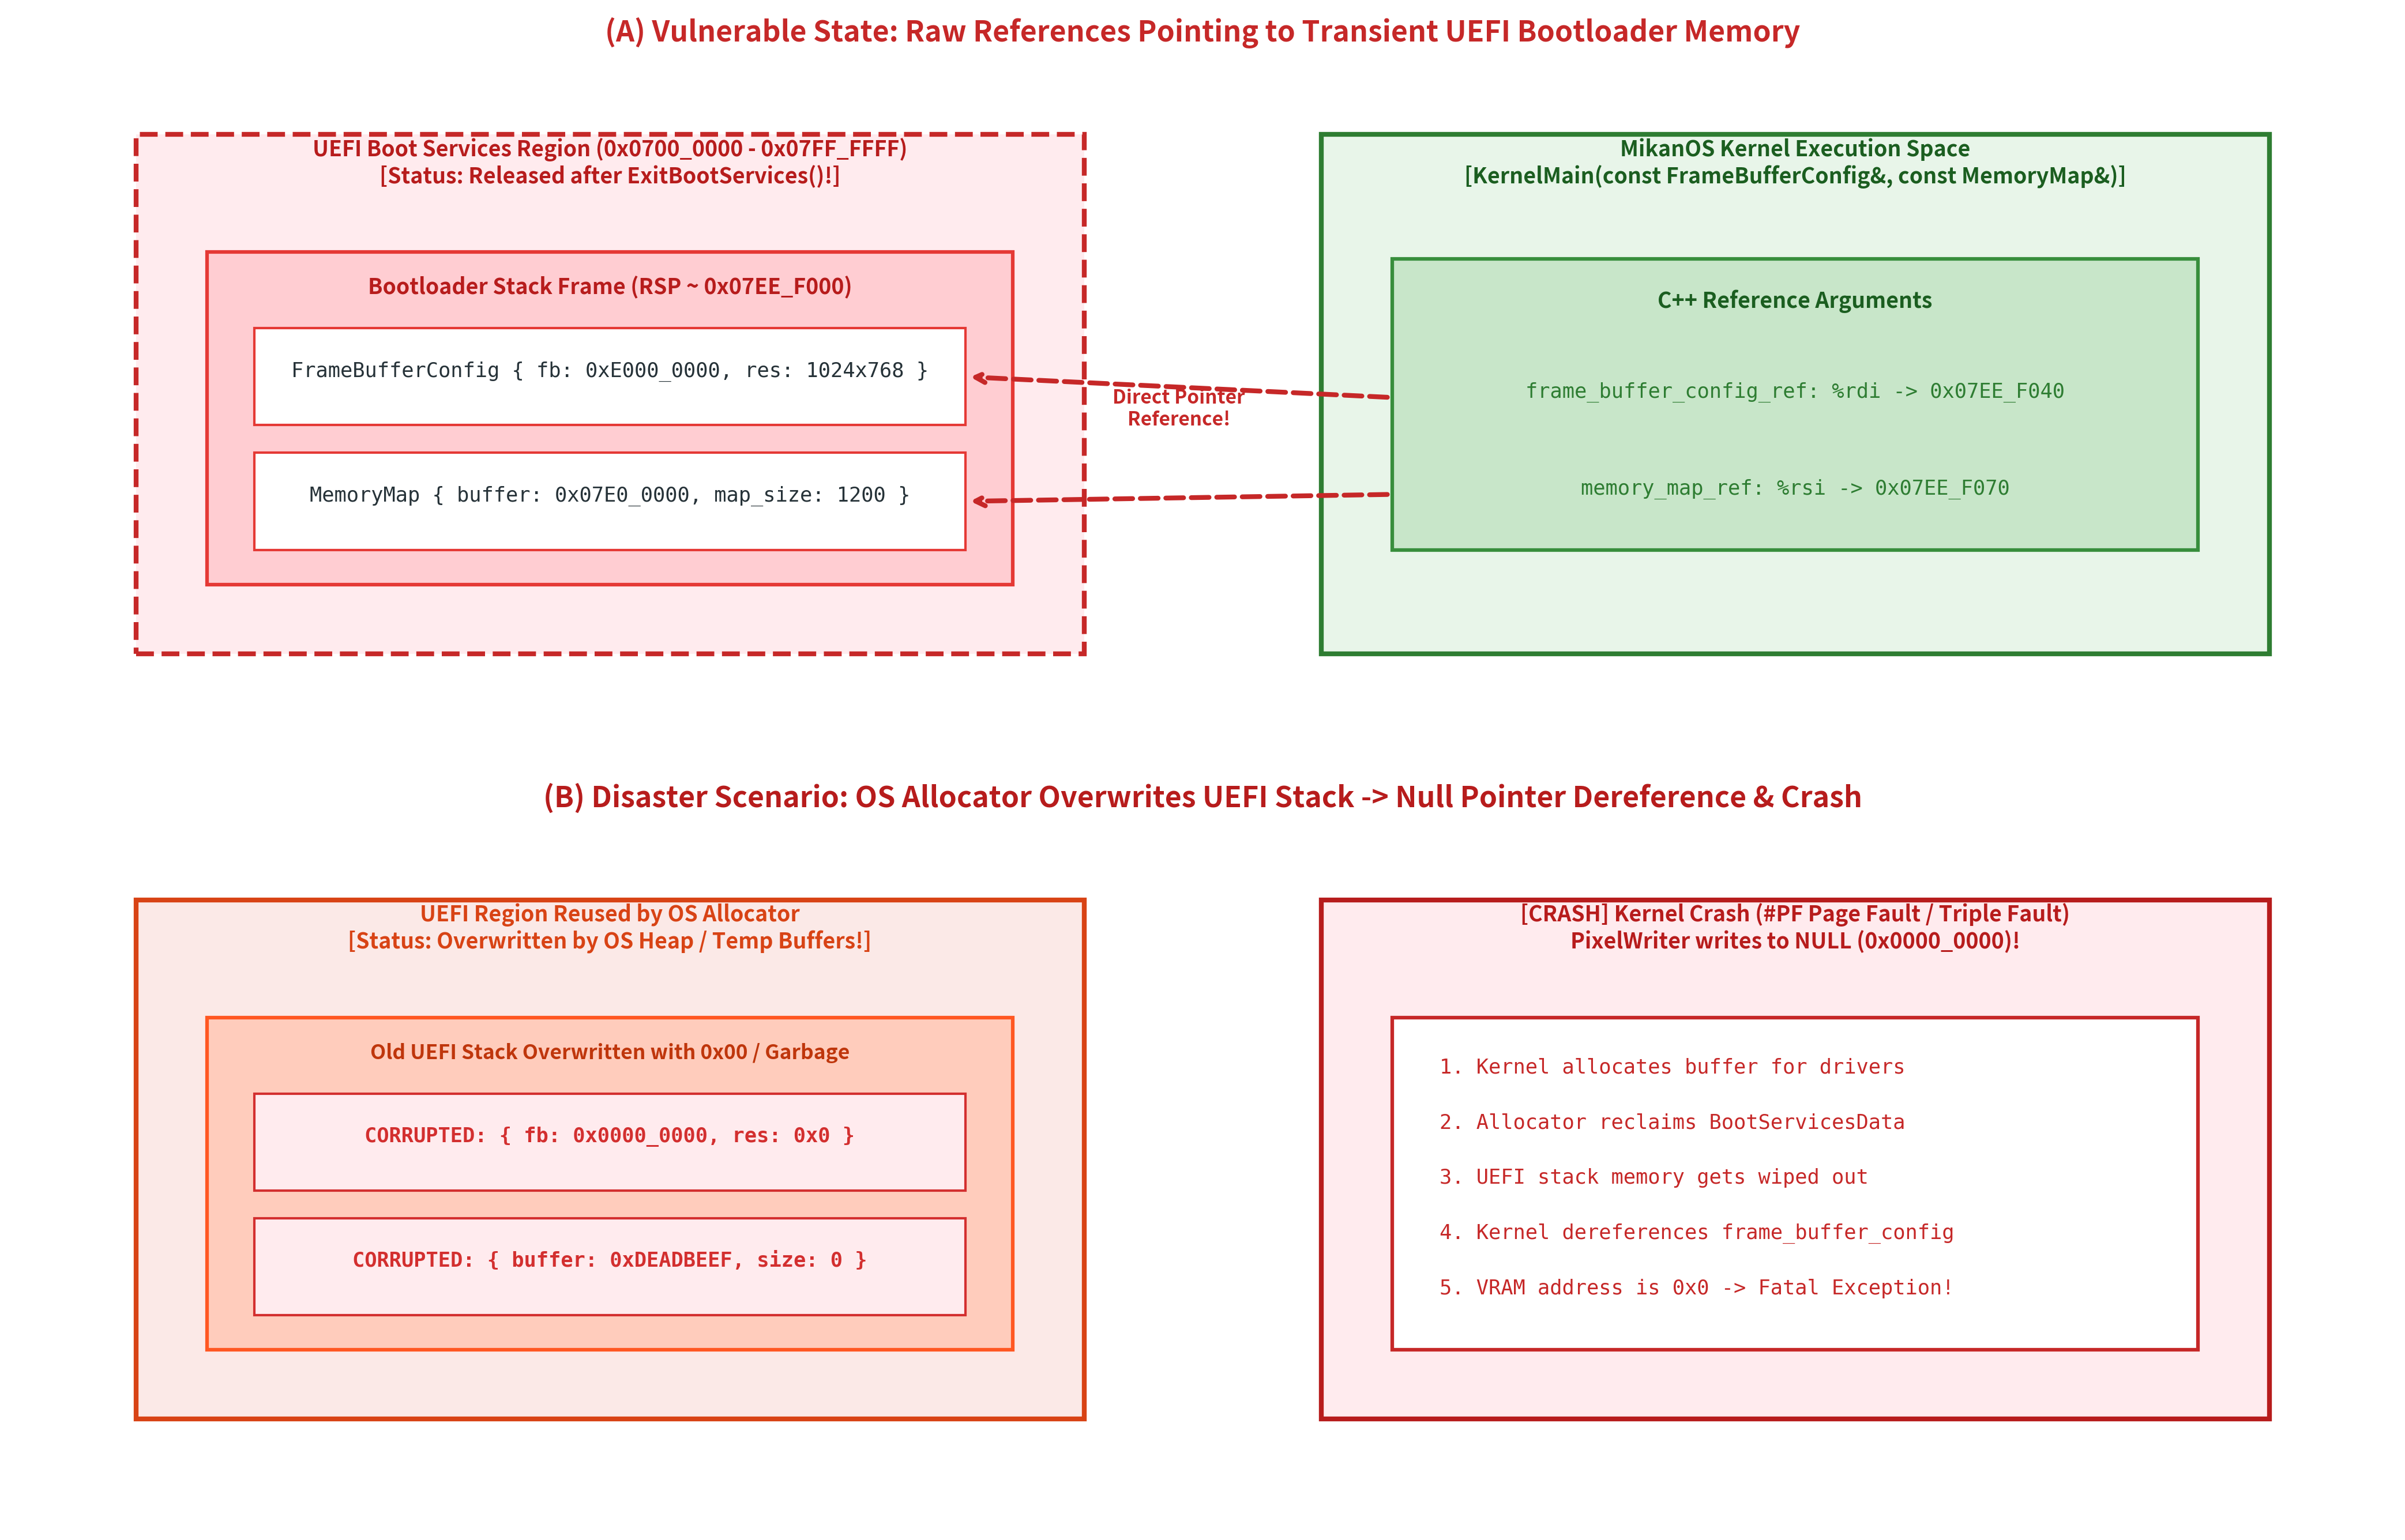

In [2]:
from common import plot_fig8_07_data_structure_relocation_danger
from IPython.display import Image, display

fig8_07_path = plot_fig8_07_data_structure_relocation_danger()
display(Image(filename=fig8_07_path))


---

## 3. C++ コピーコンストラクタによるカーネルスタックへの値コピー

### 3.1 `KernelMainNewStack` の関数シグネチャと引数

MikanOS `osbook_day08b` では、この問題を解決するために以下の設計変更を行いました：

1. カーネル専用の静的スタック配列 `kernel_main_stack`（1 MiB）を `.bss` 領域に用意する（※スタック切り替えの低レベルアセンブリ機構は次節 8.4節で詳解）。
2. 新しいスタックに切り替えた上で、エントリポイント `KernelMainNewStack` を呼び出す。
3. `KernelMainNewStack` の冒頭で、参照引数を **ローカル変数へ値コピー（Value Copy）** する！

```cpp
// kernel/main.cpp (osbook_day08b)

alignas(16) uint8_t kernel_main_stack[1024 * 1024];

extern "C" void KernelMainNewStack(
    const FrameBufferConfig& frame_buffer_config_ref,
    const MemoryMap& memory_map_ref) {
  FrameBufferConfig frame_buffer_config{frame_buffer_config_ref};
  MemoryMap memory_map{memory_map_ref};
```

### 3.2 コピーコンストラクタ（Copy Constructor）のメモリ動作

この2行のコードによって、メモリ上では何が起こるでしょうか？

```cpp
FrameBufferConfig frame_buffer_config{frame_buffer_config_ref};
```
- `frame_buffer_config_ref` は、レジスタ `%rdi` 経由で渡された UEFI スタック上のアドレス（例: `0x07EE_F040`）を参照しています。
- C++ の一様初期化（Uniform Initialization `{}`) により、コンパイラ自動生成のデフォルトコピーコンストラクタ（全メンバのビット単位コピー `memcpy` 相当）が実行されます。
- 新しく作られた変数 `frame_buffer_config` は、**現在のスタック（新しく切り替えられた `kernel_main_stack`）上のスタックフレーム** に確保されます。
- `sizeof(FrameBufferConfig)` = 24 バイトの全フィールド（`frame_buffer`, `pixels_per_scan_line`, `horizontal_resolution`, `vertical_resolution`, `pixel_format`）が安全なカーネルスタックへ複製されます。

```cpp
MemoryMap memory_map{memory_map_ref};
```
- 同様に、`sizeof(MemoryMap)` = 48 バイトの全フィールド（`buffer_size`, `buffer`, `map_size`, `map_key`, `descriptor_size`, `descriptor_version`）がカーネルスタックへ複製されます。

これ以降、カーネルの処理コード（`pixel_writer` の初期化やメモリマップ走査ループ）はすべて **カーネルスタック上のローカル変数（`frame_buffer_config`, `memory_map`）を参照** するため、古い UEFI スタックがどれだけ破壊されても何の影響も受けなくなります！


---

## 4. Figure 8.8: スタック分離アーキテクチャと値コピー退避

古い UEFI スタックから、`.bss` 内の専用カーネルスタックへのデータ退避アーキテクチャを以下に図解します。


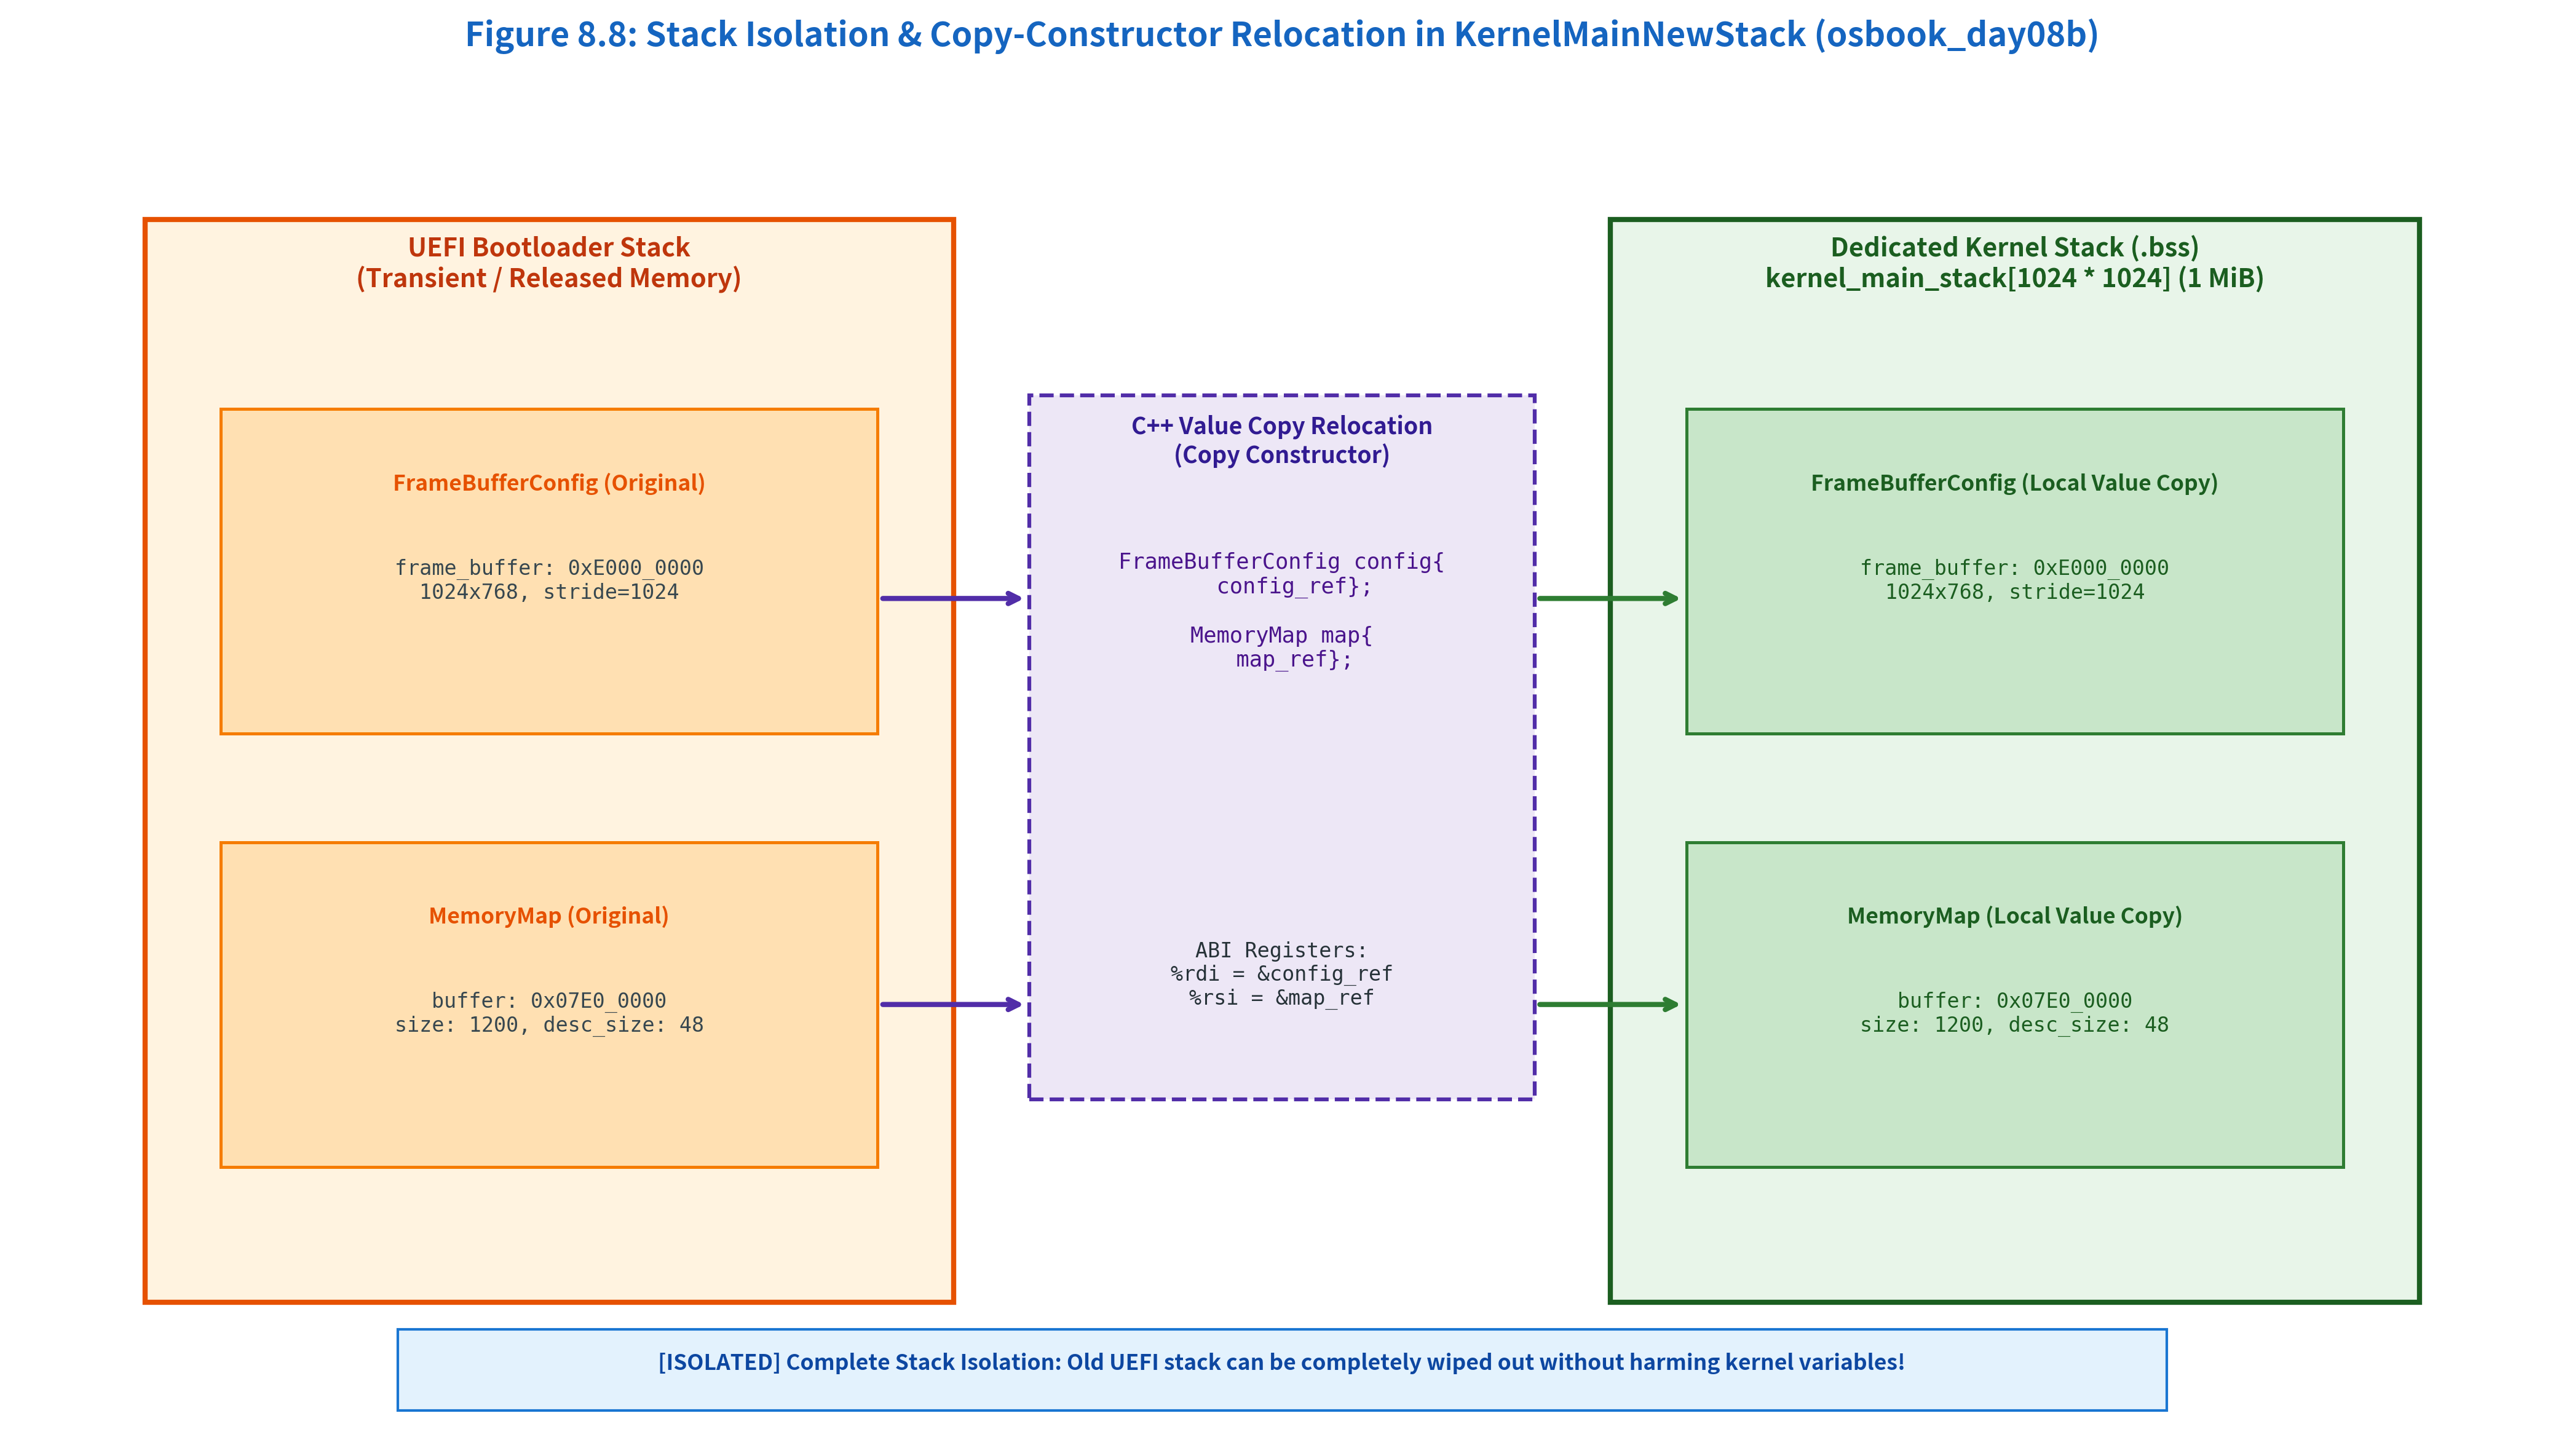

In [3]:
from common import plot_fig8_08_copy_constructor_and_stack_isolation
from IPython.display import Image, display

fig8_08_path = plot_fig8_08_copy_constructor_and_stack_isolation()
display(Image(filename=fig8_08_path))


---

## 5. ディープコピー vs シャローコピー（重要な落とし穴とライフタイム設計）

### 5.1 `MemoryMap::buffer` のシャローコピー特性

ここで、鋭い読者は重大な疑問を抱くはずです：

> **疑問**:
> `MemoryMap memory_map{memory_map_ref};` を実行したとき、`memory_map` 構造体そのものはカーネルスタックにコピーされた。
> しかし、メンバ `void* buffer;` は **ポインタ値そのものがコピーされただけ（シャローコピー / Shallow Copy）** ではないか？
> 実際のディスクリプタ配列が格納されているメモリ実体（`0x07E0_0000` 番地付近）は、依然として UEFI の `BootServicesData` 領域に残ったままなのでは？

この指摘は **完全に正しい** です。
C++ の構造体コピーにおいて、ポインタメンバはその指す先の実体（バッファ領域）までは自動複製されません（ディープコピー / Deep Copy ではない）。

```
[Kernel Stack]
memory_map {
  buffer_size: 4096
  buffer: ---------> 指している先は依然として UEFI 領域 (0x07E0_0000)!
  map_size: 1200
  ...
}
```

### 5.2 なぜバッファ自身をディープコピーしなくても安全なのか？（2つのフェーズ分離）

では、なぜ MikanOS では `buffer` の中身までディープコピーしなくても安全に動作するのでしょうか？
その理由は、OS の初期化シーケンスにおける **「2つの実行フェーズの厳密な分離（Phase Isolation）」** にあります：

1. **フェーズ 1：メモリマップ走査・集計フェーズ（8.2節 〜 8.6節）**:
   - カーネルは起動直後に `memory_map.buffer` を走査し、空き物理 RAM の総量や配置を把握します。
   - この間、OS は **動的なメモリ割り当て（Dynamic Allocation）を一切行いません**。
   - GDT（セグメンテーション）、ページテーブル、IDT（割り込み記述子表）などは、すべてコンパイル時に静的に確保された `.bss` や `.data` 領域に配置されます。
   - したがって、UEFI の `BootServicesData` 領域（`buffer` が置かれている場所）に上書きが発生する機会は **原理的に 0** です。
2. **フェーズ 2：メモリマネージャ稼働・アロケーションフェーズ（8.7節以降）**:
   - 8.7節で登場する `BitmapMemoryManager` は、フェーズ1で走査した空きメモリ情報をすべて自身の **ビットマップ配列（`alloc_map`）** に取り込みます。
   - ビットマップの初期化が完了した瞬間、OS はもはや元の `MemoryMap` 構造体や `memory_map.buffer` を **二度と参照しません**。
   - したがって、この後にアロケータが `BootServicesData` 領域を他の用途に払い出して上書きしても、OS の動作にはまったく影響がないのです！

### 5.3 恒久保持する場合の要件

もし OS が実行中にいつでも UEFI メモリマップを再検査できる機能（例: `/proc/iomem` のようなデバッグコマンド）を提供したい場合はどうすべきでしょうか？
その場合は、以下のいずれかの対策が必要です：
- **ディープコピー方式**: カーネル自身の静的バッファにディスクリプタ配列を丸ごと `memcpy` して退避する。
- **予約マーク方式**: ビットマップメモリマネージャ初期化時に、`memory_map.buffer` が占有している物理ページフレームをあらかじめ「使用中（Allocation済み）」としてマークし、アロケータが他用途に払い出さないよう保護する。

MikanOS では設計の簡素化のため、「初期化完了後は元のメモリマップバッファを破棄してよい」という方針を採用しています。


---

## 6. Figure 8.9: シャローコピーの生存期間解析と実行フェーズ境界

シャローコピーのポインタ関係と、フェーズ分離による安全性保証のタイムラインを以下に示します。


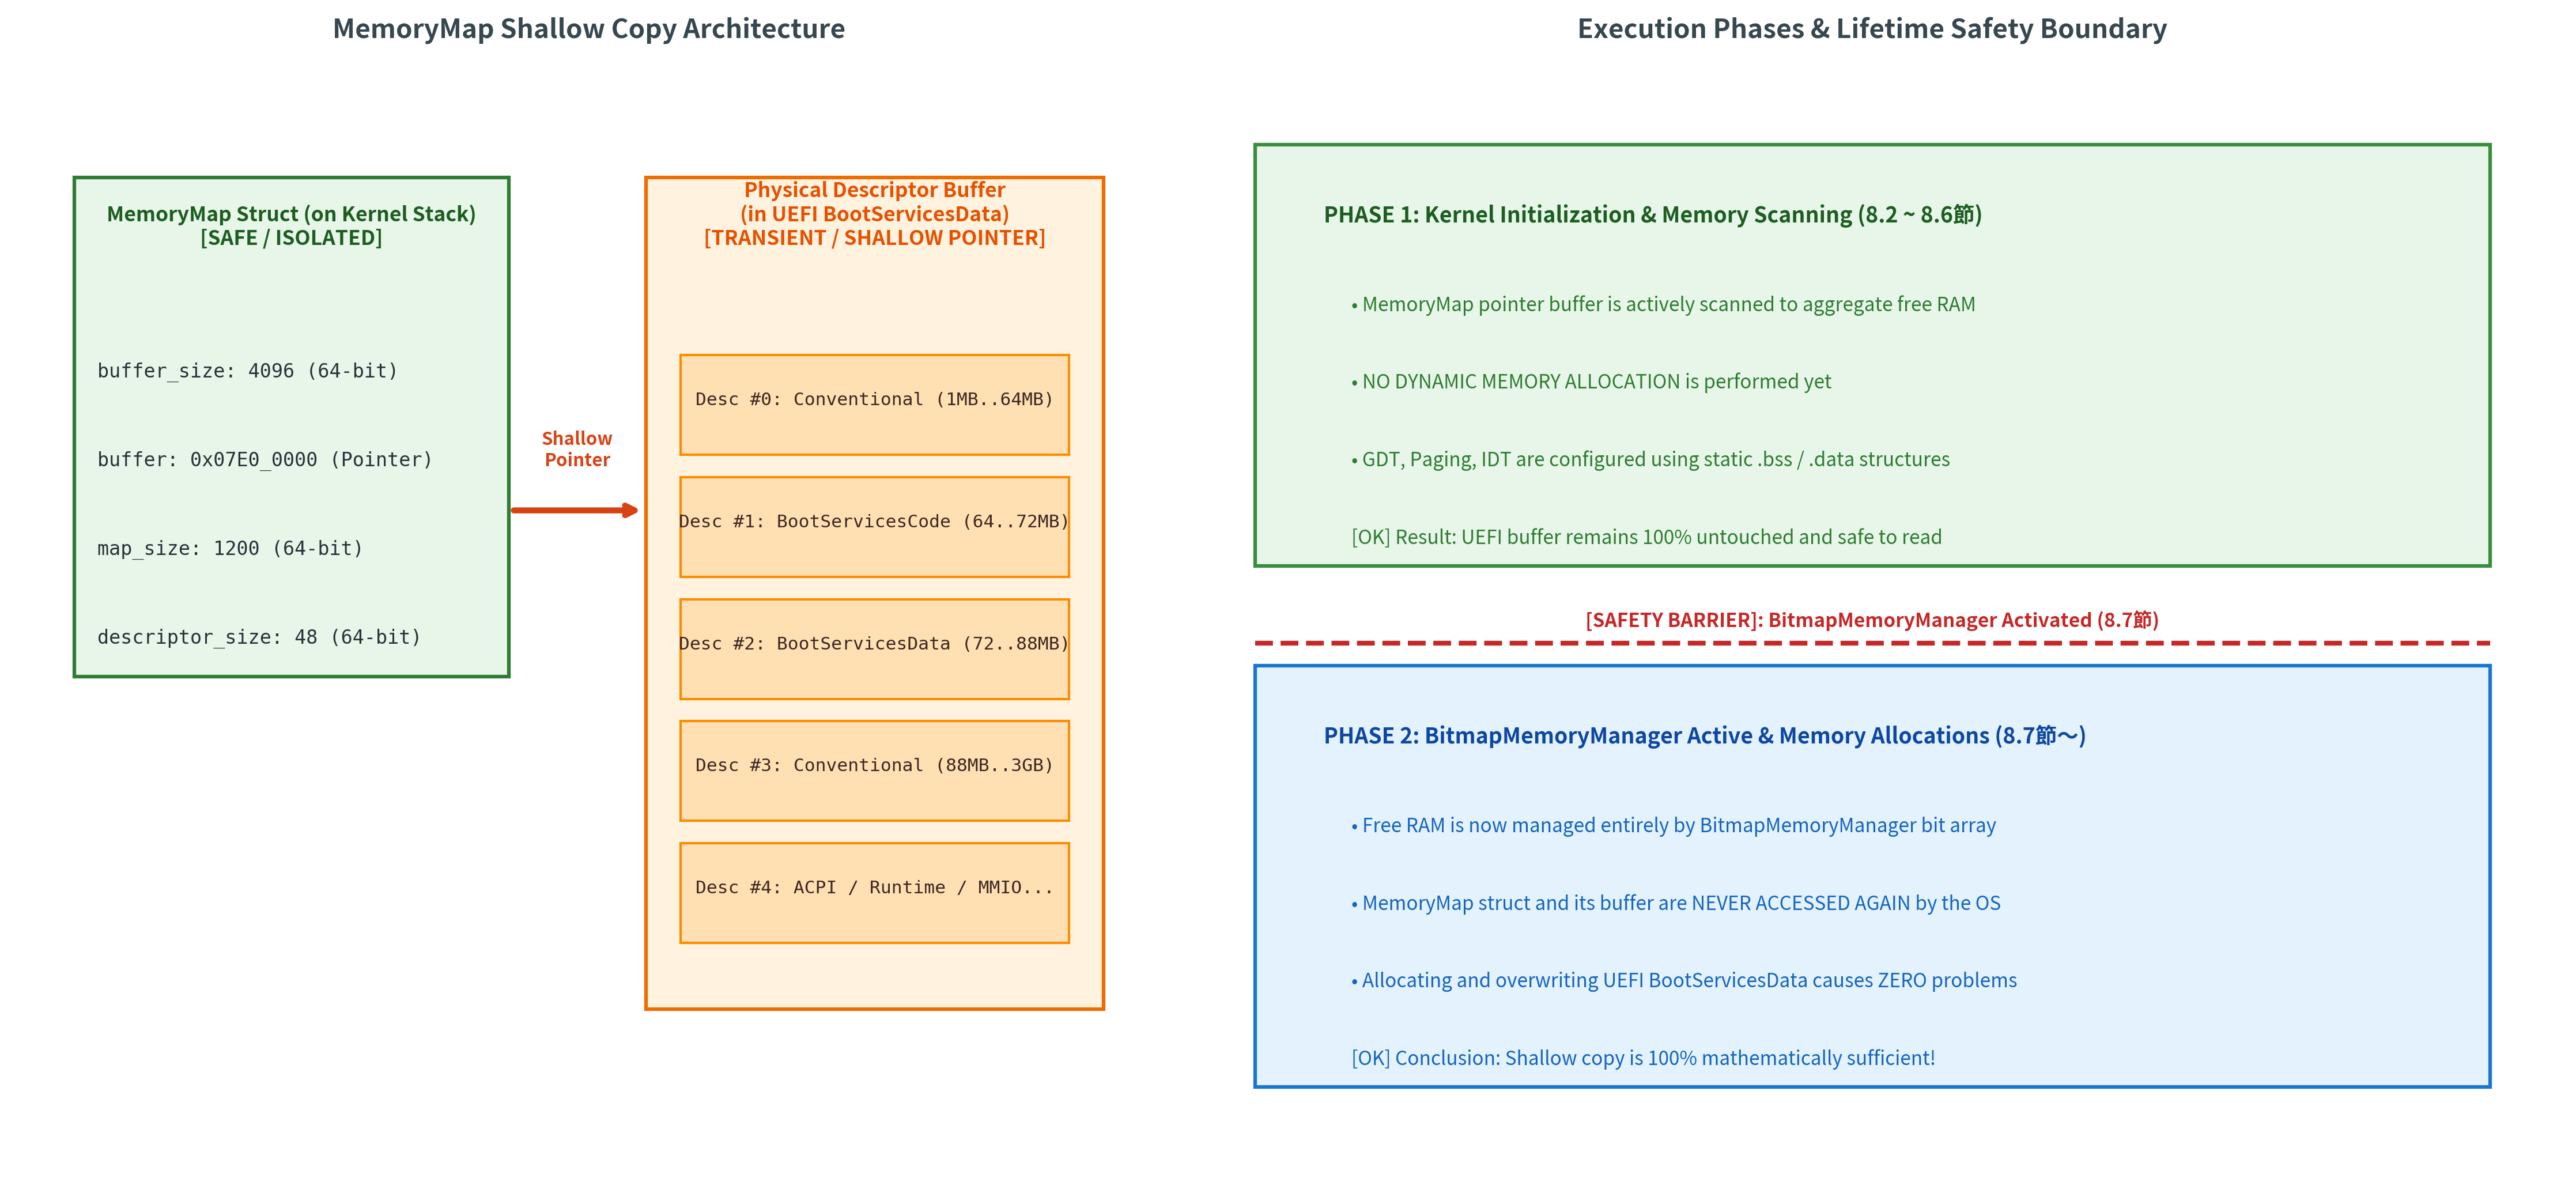

In [4]:
from common import plot_fig8_09_memory_map_buffer_lifetime_safety
from IPython.display import Image, display

fig8_09_path = plot_fig8_09_memory_map_buffer_lifetime_safety()
display(Image(filename=fig8_09_path))


---

## 7. `IsAvailable()` 関数の整理とカプセル化

### 7.1 `kernel/memory_map.hpp` のインライン関数

前節（8.2節）では、利用可能メモリの判定を `KernelMain` 内で以下のように配列ループで書いていました：

```cpp
// 8.2節 (osbook_day08a): main.cpp 内でのベタ書きループ
const std::array available_memory_types{
  MemoryType::kEfiBootServicesCode,
  MemoryType::kEfiBootServicesData,
  MemoryType::kEfiConventionalMemory,
};

for (int i = 0; i < available_memory_types.size(); ++i) {
  if (desc->type == available_memory_types[i]) { ... }
}
```

MikanOS `osbook_day08b` では、この判定ロジックをヘッダファイル `kernel/memory_map.hpp` に集約し、インライン関数 `IsAvailable()` としてカプセル化しました：

```cpp
// kernel/memory_map.hpp (osbook_day08b)

// #@@range_begin(is_available)
inline bool IsAvailable(MemoryType memory_type) {
  return
    memory_type == MemoryType::kEfiBootServicesCode ||
    memory_type == MemoryType::kEfiBootServicesData ||
    memory_type == MemoryType::kEfiConventionalMemory;
}

const int kUEFIPageSize = 4096;
// #@@range_end(is_available)
```

### 7.2 カプセル化による設計上のメリット
1. **保守性の向上**: 「OS がどの UEFI メモリを再利用するか」のポリシ定義がヘッダの1箇所に集中し、後から `kEfiLoaderData` を回収対象に加えるなどの変更が容易になります。
2. **実行速度の最適化**: 3要素の配列を走査する線形探索（ループ・比較）から、3つの論理 OR（`||`）による短絡評価（Short-circuit evaluation）へと簡素化され、コンパイラによって最小限の条件分岐命令（またはビットマスク比較）に最適化されます。
3. **可読性の向上**: 走査ループが `if (IsAvailable(static_cast<MemoryType>(desc->type)))` と1行で明快に記述できるようになりました。
4. **ページサイズ定数の導入**: UEFI の物理ページサイズが 4096 バイト（4 KiB）であることを表す定数 `kUEFIPageSize = 4096` を明示し、マジックナンバーの排除を進めました。


---

## 8. C++20 スタンドアロン検証コードの対話型コンパイルと実行

ホスト側環境（Linux / WSL / Google Colab）において、MikanOS のデータ退避機構・コピーコンストラクタ動作・`IsAvailable()` ロジックをホスト側 C++20 でコンパイルし、アサーション自動検証を実行します。


In [5]:
%%writefile /tmp/test_relocate_data.cpp
#include <iostream>
#include <cstdint>
#include <cassert>
#include <cstring>

enum PixelFormat {
  kPixelRGBResv8BitPerColor,
  kPixelBGRResv8BitPerColor,
};

struct FrameBufferConfig {
  uint8_t* frame_buffer;
  uint32_t pixels_per_scan_line;
  uint32_t horizontal_resolution;
  uint32_t vertical_resolution;
  enum PixelFormat pixel_format;
};

struct MemoryMap {
  unsigned long long buffer_size;
  void* buffer;
  unsigned long long map_size;
  unsigned long long map_key;
  unsigned long long descriptor_size;
  uint32_t descriptor_version;
};

enum class MemoryType : uint32_t {
  kEfiReservedMemoryType,
  kEfiLoaderCode,
  kEfiLoaderData,
  kEfiBootServicesCode,
  kEfiBootServicesData,
  kEfiRuntimeServicesCode,
  kEfiRuntimeServicesData,
  kEfiConventionalMemory,
  kEfiUnusableMemory,
  kEfiACPIReclaimMemory,
  kEfiACPIMemoryNVS,
  kEfiMemoryMappedIO,
  kEfiMemoryMappedIOPortSpace,
  kEfiPalCode,
  kEfiPersistentMemory,
  kEfiMaxMemoryType
};

inline bool IsAvailable(MemoryType memory_type) {
  return
    memory_type == MemoryType::kEfiBootServicesCode ||
    memory_type == MemoryType::kEfiBootServicesData ||
    memory_type == MemoryType::kEfiConventionalMemory;
}

int main() {
  std::cout << "[Step 1] Structure Sizes and Alignment:\n";
  std::cout << "  sizeof(FrameBufferConfig) = " << sizeof(FrameBufferConfig) << " bytes\n";
  std::cout << "  sizeof(MemoryMap)         = " << sizeof(MemoryMap) << " bytes\n";
  assert(sizeof(FrameBufferConfig) == 24);
  assert(sizeof(MemoryMap) == 48);

  std::cout << "[Step 2] IsAvailable() Logic Verification:\n";
  assert(IsAvailable(MemoryType::kEfiBootServicesCode) == true);
  assert(IsAvailable(MemoryType::kEfiBootServicesData) == true);
  assert(IsAvailable(MemoryType::kEfiConventionalMemory) == true);
  assert(IsAvailable(MemoryType::kEfiReservedMemoryType) == false);
  assert(IsAvailable(MemoryType::kEfiRuntimeServicesCode) == false);
  std::cout << "  -> Exactly 3 memory types confirmed reusable.\n";

  std::cout << "[Step 3] Value-Copy Relocation Verification:\n";
  alignas(16) uint8_t uefi_stack[256];
  auto* uefi_fb = reinterpret_cast<FrameBufferConfig*>(&uefi_stack[0]);
  uefi_fb->frame_buffer = reinterpret_cast<uint8_t*>(0xE0000000ULL);
  uefi_fb->horizontal_resolution = 1024;
  uefi_fb->vertical_resolution = 768;

  // Emulating KernelMainNewStack value copy
  const FrameBufferConfig& fb_ref = *uefi_fb;
  FrameBufferConfig kernel_fb{fb_ref};

  assert(&kernel_fb != &fb_ref); // Isolated addresses

  // Wiping UEFI stack
  std::memset(uefi_stack, 0xCC, sizeof(uefi_stack));

  // Verify kernel copy is unharmed
  assert(kernel_fb.frame_buffer == reinterpret_cast<uint8_t*>(0xE0000000ULL));
  assert(kernel_fb.horizontal_resolution == 1024);
  assert(kernel_fb.vertical_resolution == 768);
  std::cout << "  -> Value copy perfectly isolated kernel variables from UEFI memory wipe!\n";

  std::cout << "\n[SUCCESS] C++20 Verification Completed with 0 Errors.\n";
  return 0;
}


Overwriting /tmp/test_relocate_data.cpp


In [6]:
!g++ -std=c++20 -O2 -Wall -Wextra /tmp/test_relocate_data.cpp -o /tmp/test_relocate_data
!/tmp/test_relocate_data


[Step 1] Structure Sizes and Alignment:
  sizeof(FrameBufferConfig) = 24 bytes
  sizeof(MemoryMap)         = 48 bytes
[Step 2] IsAvailable() Logic Verification:
  -> Exactly 3 memory types confirmed reusable.
[Step 3] Value-Copy Relocation Verification:
  -> Value copy perfectly isolated kernel variables from UEFI memory wipe!

[SUCCESS] C++20 Verification Completed with 0 Errors.


---

## 9. Python によるデータ退避シミュレーションとアサーション検証

Python シミュレータ `DataRelocationSimulator` を用いて、未退避時のクラッシュ挙動と退避時の安全性を定量比較します。


In [7]:
from common import DataRelocationSimulator

sim = DataRelocationSimulator()

print("=== 1. 未退避（参照のまま）のクラッシュシミュレーション ===")
corrupt_res = sim.simulate_unprotected_reference_corruption()
print(f"安全フラグ: {corrupt_res['safe']}")
print(f"元のアドレス: 0x{corrupt_res['original_fb_addr']:X}")
print(f"破壊後アドレス: 0x{corrupt_res['corrupted_fb_addr']:X}")
print(f"障害モード: {corrupt_res['failure_mode']}")

print("\n=== 2. 値コピー退避（Relocation）後の安全性検証 ===")
safe_res = sim.simulate_relocated_value_copy()
print(f"安全フラグ: {safe_res['safe']}")
print(f"カーネルVRAMアドレス: 0x{safe_res['kernel_fb_addr']:X}")
print(f"UEFIスタック状態: {safe_res['uefi_stack_status']}")
print(f"カーネルスタック状態: {safe_res['kernel_stack_status']}")

print("\n=== 3. シャローコピーの生存期間解析 ===")
life_res = sim.analyze_shallow_copy_lifetime()
print(f"構造体の配置場所: {life_res['struct_location']}")
print(f"バッファの配置場所: {life_res['buffer_location']}")
print(f"走査フェーズ (Phase 1) の安全性: {life_res['phase1_scanning']['is_buffer_safe']} ({life_res['phase1_scanning']['reason']})")
print(f"確保フェーズ (Phase 2) の安全性: {life_res['phase2_allocation']['is_buffer_safe']} ({life_res['phase2_allocation']['reason']})")


=== 1. 未退避（参照のまま）のクラッシュシミュレーション ===
安全フラグ: False
元のアドレス: 0xE0000000
破壊後アドレス: 0x0
障害モード: Kernel crashes on page fault when dereferencing frame_buffer or invalid map size

=== 2. 値コピー退避（Relocation）後の安全性検証 ===
安全フラグ: True
カーネルVRAMアドレス: 0xE0000000
UEFIスタック状態: Overwritten with garbage (safely isolated)
カーネルスタック状態: Intact and fully valid

=== 3. シャローコピーの生存期間解析 ===
構造体の配置場所: Kernel Stack (Isolated, Safe)
バッファの配置場所: UEFI BootServicesData (Transient, Reusable)
走査フェーズ (Phase 1) の安全性: True (Memory manager only scans and aggregates descriptors; does not allocate memory yet.)
確保フェーズ (Phase 2) の安全性: False (Allocations may overwrite UEFI memory; however, memory_map.buffer is no longer accessed.)


---

## 10. まとめと次節（8.4節 スタック領域の移動）への布石

本節では、UEFI からカーネルへ渡された重要データ構造をカーネル管理下のスタックへ退避させ、過渡的メモリの危険性を排除するアーキテクチャを学びました。

### 📌 本節で達成したことの要約
1. **UEFI 過渡的メモリの危険性の解明**:
   - `ExitBootServices()` 後に解放されるブートサービス領域に置かれたデータ構造をポインタ参照し続けると、メモリマネージャの再利用によって上書き破壊され、OS が即座にクラッシュすることを明らかにしました。
2. **コピーコンストラクタによる完全退避**:
   - `KernelMainNewStack` の冒頭でローカル変数への値コピーを行うことで、構造体の全フィールドを新しいカーネルスタックへ複製し、古いスタックの破壊から完全に隔離できることを実証しました。
3. **シャローコピーとフェーズ分離の数理**:
   - `MemoryMap::buffer` がポインタのシャローコピーであっても、メモリ走査完了までアロケータを動かさない「フェーズ分離」によって安全性が完全に担保される理由を導出しました。
4. **`IsAvailable()` インライン関数の整理**:
   - `kernel/memory_map.hpp` における利用可能メモリ判定のカプセル化と、ページサイズ定数 `kUEFIPageSize = 4096` の導入によるコード品質の向上を確認しました。

> [!WARNING]
> **次なる課題：スタックポインタ（RSP）自体の危険性（8.4節への布石）**
> データ構造自体はローカル変数にコピーできるようになりました。
> しかし、**いまコードが実行されている「スタックそのもの」** はどこにあるでしょうか？
> 
> そうです！ CPU のスタックポインタ（`RSP`）は、まだ **UEFI ファームウェアが用意した過渡的なスタック領域** を指したまま動いています！
> ローカル変数をいくらスタックに作っても、スタック自体が UEFI 領域にあっては根本的な解決になりません。
> 
> 次節（8.4節）では、`.bss` 領域に確保した 1 MiB の独自スタック配列 `kernel_main_stack` へ、**x86-64 アセンブリ（`asmfunc.asm`）を用いて `RSP` レジスタを強制的に切り替える低レベル機構** を実装・探求します！
